# 03. Modelos No Supervisados, Clustering y Priorización para Analistas AML — Unidad 2
**Proyecto:** Sistema de IA para Detección y Priorización de Fraude (IBM TabFormer)  
**Unidad 2:** Clustering, Análisis de Componentes Principales y Priorización Operativa  
**Entorno:** Python 3.12 | scikit-learn | SciPy | Polars | Matplotlib | Seaborn

---

### Objetivos del Notebook:
1. **Modelos No Supervisados y Reducción de Dimensionalidad**:
   - Utilizar **estrictamente características de comportamiento transaccional** (`amount_log`, `hour_sin`, `hour_cos`, `day_of_week`, `is_weekend`, `is_night`, `Use Chip`) escaladas con `StandardScaler`.
   - **Regla Estricta:** Prohibido incluir `Is Fraud?` o `is_fraud` en el ajuste no supervisado.
   - **PCA (Análisis de Componentes Principales):** Proyectar las transacciones en 2D y reportar la varianza explicada acumulada.
   - **K-Means:** Evaluar $k \in \{2, 3, 4, 5, 6, 7, 8\}$ sobre una muestra representativa de entrenamiento registrando Inercia y Silhouette Score. Graficar la curva del Codo (Elbow) y Silhouette para seleccionar el $k$ óptimo.
   - **Clustering Jerárquico (`AgglomerativeClustering`):** Ajustar sobre una muestra reproducible (10,000 registros para viabilidad de memoria), graficar el Dendrograma (Ward) y comparar su Silhouette Score contra K-Means.
   - **Perfiles Accionables:** Interpretar cada cluster en sus unidades originales y realizar un cruce post-hoc con la tasa de fraude observada. Exportar `data/processed/perfiles_clusters.csv`.
2. **Optimización de Umbral y Capacidad Operativa para Analistas AML**:
   - Evaluar diferentes umbrales de decisión sobre predicciones de validación (nunca sobre el test final).
   - Generar la curva de compromiso entre alertas generadas, Precision, Recall y F1. Guardar `data/processed/optimizacion_umbral.csv`.
3. **Análisis de Impacto Económico Hipotético**:
   - Evaluar la sensibilidad del beneficio neto bajo supuestos bancarios transparentes (costo operativo por alerta revisada vs importe fraudulento prevenido).
4. **Tabla Operativa Final de Transacciones Priorizadas**:
   - Generar `data/predictions/transacciones_priorizadas.csv` sobre un lote de inferencia sin la etiqueta de fraude, ordenado por `risk_score` descendente y clasificado en niveles de prioridad (`ALTA`, `MEDIA`, `BAJA`, `OUT_OF_COHORT_REVIEW`) con acciones recomendadas para el analista humano.


In [1]:
import sys
from pathlib import Path

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR
while not (PROJECT_ROOT / "notebooks").exists() and PROJECT_ROOT.parent != PROJECT_ROOT:
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from notebooks._comun.config import (
    PROCESSED_DATA_DIR,
    PREDICTIONS_DIR,
    ARTIFACTS_DIR,
    RANDOM_STATE,
    CLUSTER_PROFILES_FILE,
    THRESHOLD_OPT_FILE,
    PRIORITIZED_TXNS_FILE,
    INFERENCE_SAMPLE_FILE,
    MODEL_U2_ARTIFACT,
    PREPROCESSOR_U2_ARTIFACT,
    CLUSTERING_FEATURES,
    SELECTED_FEATURES_U2,
)
from notebooks._comun.data_utils import (
    load_artifact,
    add_u2_engineered_features,
)
print(f"Raíz del proyecto: {PROJECT_ROOT}")


Raíz del proyecto: /home/glender/ProyectosUNi/iaupeu


In [2]:
import time
import polars as pl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, precision_recall_curve, f1_score, precision_score, recall_score

# Estilo visual
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

TRAIN_U2_FILE = PROCESSED_DATA_DIR / "train_u2.parquet"
train_df = pl.read_parquet(TRAIN_U2_FILE)
print(f"Dataset de desarrollo cargado: {train_df.shape[0]:,} transacciones")


Dataset de desarrollo cargado: 252,670 transacciones


## 1. Preparación de Características Conductuales Transaccionales
Para el modelado no supervisado, utilizamos **únicamente variables conductuales** de la transacción (monto transformado, ciclo horario, día de semana y modalidad de pago).
> **Principio Ético y Metodológico:** La etiqueta `Is Fraud?` o `is_fraud` está **estrictamente excluida** para asegurar un aprendizaje no supervisado genuino.


In [3]:
# Variables numéricas y categóricas para clustering
cluster_num_cols = ["amount_log", "hour_sin", "hour_cos", "day_of_week", "is_weekend", "is_night"]
cluster_cat_cols = ["Use Chip"]
all_cluster_features = cluster_num_cols + cluster_cat_cols

cluster_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), cluster_num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cluster_cat_cols),
    ],
    remainder="drop"
)

# Muestra representativa reproducible para clustering (40,000 transacciones para cálculo ágil de siluetas)
np.random.seed(RANDOM_STATE)
df_cluster_sample = train_df.sample(n=40000, seed=RANDOM_STATE)
X_cluster_df = df_cluster_sample.select(all_cluster_features).to_pandas()

X_cluster_scaled = cluster_preprocessor.fit_transform(X_cluster_df)
print(f"Matriz de clustering escalada: {X_cluster_scaled.shape[0]:,} filas x {X_cluster_scaled.shape[1]} dimensiones")


Matriz de clustering escalada: 40,000 filas x 9 dimensiones


## 2. Reducción de Dimensionalidad con PCA
Aplicamos Análisis de Componentes Principales ($PCA$) para proyectar la estructura transaccional en un espacio bidimensional interpretable.


Varianza explicada por PC1: 27.78%
Varianza explicada por PC2: 22.45%
Varianza acumulada (2D):    50.22%


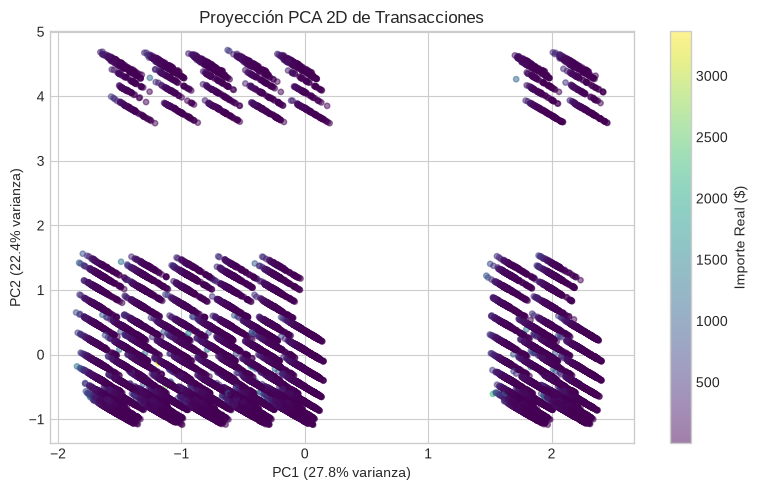

In [4]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_cluster_scaled)

var_exp = pca.explained_variance_ratio_
print(f"Varianza explicada por PC1: {var_exp[0]*100:.2f}%")
print(f"Varianza explicada por PC2: {var_exp[1]*100:.2f}%")
print(f"Varianza acumulada (2D):    {np.sum(var_exp)*100:.2f}%")

# Gráfico de proyección 2D
plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df_cluster_sample["Amount"].to_numpy(),
            cmap="viridis", alpha=0.5, s=15)
plt.colorbar(label="Importe Real ($)")
plt.title("Proyección PCA 2D de Transacciones")
plt.xlabel(f"PC1 ({var_exp[0]*100:.1f}% varianza)")
plt.ylabel(f"PC2 ({var_exp[1]*100:.1f}% varianza)")
plt.tight_layout()
plt.show()


## 3. K-Means: Búsqueda del $k$ Óptimo (Curva del Codo y Silhouette)
Evaluamos $k \in \{2, 3, 4, 5, 6, 7, 8\}$ calculando la Inercia (suma de distancias al cuadrado a los centroides) y el Silhouette Score (cohesión interna vs separación externa).


Evaluando K-Means para k de 2 a 8...


  k=2 | Inercia: 193,594.6 | Silhouette: 0.2963 (5.6s)


  k=3 | Inercia: 147,920.4 | Silhouette: 0.3362 (6.1s)


  k=4 | Inercia: 121,316.9 | Silhouette: 0.2838 (9.6s)


  k=5 | Inercia: 107,937.3 | Silhouette: 0.2571 (7.6s)


  k=6 | Inercia: 96,701.1 | Silhouette: 0.2582 (7.4s)


  k=7 | Inercia: 87,056.3 | Silhouette: 0.2643 (7.5s)


  k=8 | Inercia: 81,490.7 | Silhouette: 0.2600 (8.5s)


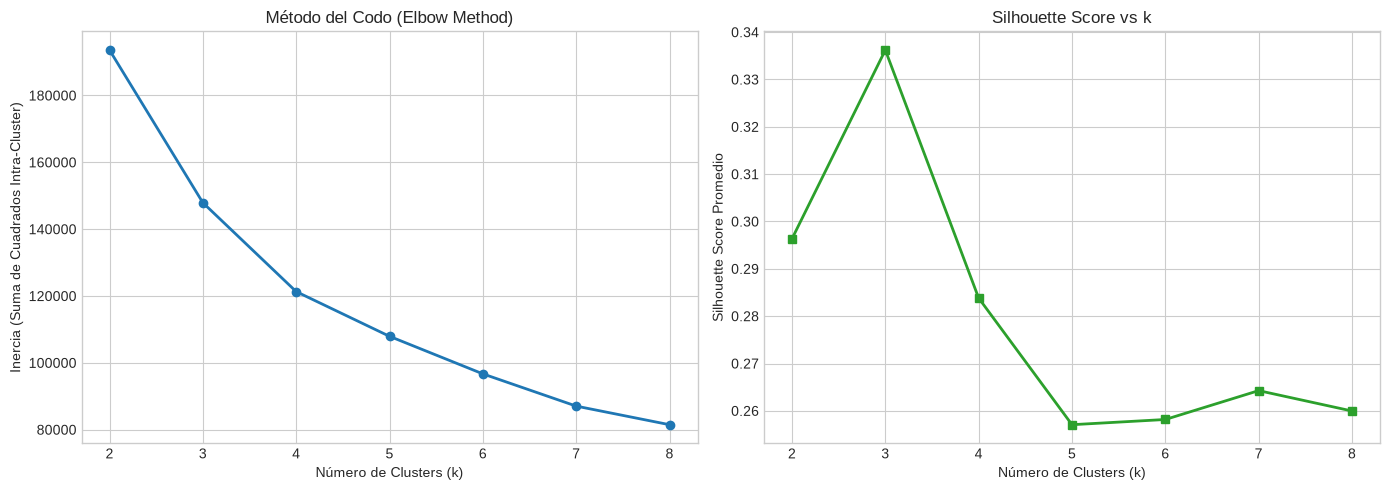

In [5]:
k_range = list(range(2, 9))
inertias = []
silhouette_scores = []

# Submuestra para cálculo rápido de Silhouette (15,000 registros)
sub_sil_idx = np.random.choice(len(X_cluster_scaled), size=15000, replace=False)
X_sil = X_cluster_scaled[sub_sil_idx]

print("Evaluando K-Means para k de 2 a 8...")
for k in k_range:
    t0 = time.time()
    km = KMeans(n_clusters=k, init="k-means++", n_init=5, random_state=RANDOM_STATE)
    km.fit(X_cluster_scaled)
    inertias.append(km.inertia_)
    
    sil = silhouette_score(X_sil, km.predict(X_sil))
    silhouette_scores.append(sil)
    print(f"  k={k} | Inercia: {km.inertia_:,.1f} | Silhouette: {sil:.4f} ({time.time()-t0:.1f}s)")

# Gráficos de diagnóstico
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Curva del Codo (Elbow)
ax1.plot(k_range, inertias, marker="o", color="#1f77b4", lw=2)
ax1.set_title("Método del Codo (Elbow Method)")
ax1.set_xlabel("Número de Clusters (k)")
ax1.set_ylabel("Inercia (Suma de Cuadrados Intra-Cluster)")
ax1.set_xticks(k_range)

# 2. Silhouette Score
ax2.plot(k_range, silhouette_scores, marker="s", color="#2ca02c", lw=2)
ax2.set_title("Silhouette Score vs k")
ax2.set_xlabel("Número de Clusters (k)")
ax2.set_ylabel("Silhouette Score Promedio")
ax2.set_xticks(k_range)

plt.tight_layout()
plt.show()


## 4. Clustering Jerárquico Aglomerativo y Dendrograma
Ajustamos `AgglomerativeClustering` con enlace Ward sobre una muestra de 10,000 registros para viabilidad computacional de la matriz de distancias.


Calculando matriz de enlace Ward...


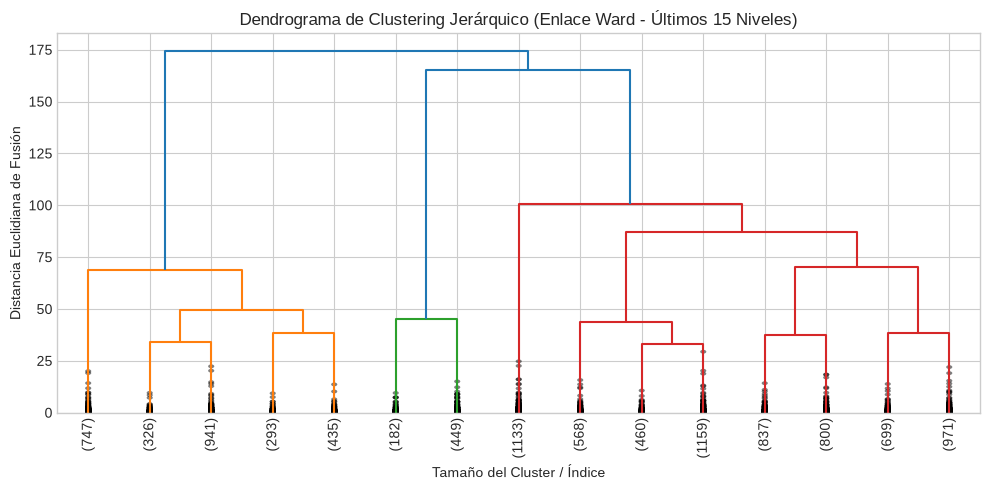

Silhouette Score de Clustering Jerárquico (k=4): 0.2850


In [6]:
# Muestra para Clustering Jerárquico (10,000 filas)
X_hier = X_cluster_scaled[:10000]

print("Calculando matriz de enlace Ward...")
Z = linkage(X_hier, method="ward")

# Dendrograma truncado
plt.figure(figsize=(10, 5))
dendrogram(Z, truncate_mode="lastp", p=15, leaf_rotation=90, leaf_font_size=10, show_contracted=True)
plt.title("Dendrograma de Clustering Jerárquico (Enlace Ward - Últimos 15 Niveles)")
plt.xlabel("Tamaño del Cluster / Índice")
plt.ylabel("Distancia Euclidiana de Fusión")
plt.tight_layout()
plt.show()

# Evaluación de Silhouette en Clustering Jerárquico para k=4
k_opt = 4
agg_cluster = AgglomerativeClustering(n_clusters=k_opt, linkage="ward")
agg_labels = agg_cluster.fit_predict(X_hier)
agg_sil = silhouette_score(X_hier, agg_labels)
print(f"Silhouette Score de Clustering Jerárquico (k={k_opt}): {agg_sil:.4f}")


## 5. Interpretación de Perfiles Accionables y Cruce Post-Hoc con Fraude
Ajustamos el modelo definitivo de K-Means con el $k$ óptimo seleccionado ($k=4$) y cruzamos los clusters resultantes con las unidades originales (importe en dólares, hora, canal) y con la **tasa de fraude observada** (análisis *post-hoc* para negocio).


In [7]:
# Ajustar K-Means definitivo
kmeans_final = KMeans(n_clusters=k_opt, init="k-means++", n_init=10, random_state=RANDOM_STATE)
cluster_labels = kmeans_final.fit_predict(X_cluster_scaled)

# Asignar cluster a la muestra
df_profile = df_cluster_sample.with_columns(pl.Series("cluster_id", cluster_labels))

# Perfiles de comportamiento en unidades originales y cruce con fraude
profiles = (
    df_profile.group_by("cluster_id")
    .agg([
        pl.len().alias("total_transacciones"),
        pl.col("Amount").median().round(2).alias("importe_mediano_$"),
        pl.col("Amount").mean().round(2).alias("importe_promedio_$"),
        pl.col("hour").mean().round(1).alias("hora_promedio"),
        pl.col("is_night").mean().round(3).alias("pct_nocturnas"),
        pl.col("is_weekend").mean().round(3).alias("pct_fin_de_semana"),
        (pl.col("Use Chip") == "Online Transaction").mean().round(3).alias("pct_online"),
        pl.col("is_fraud").sum().alias("fraudes_detectados"),
    ])
    .with_columns([
        (pl.col("fraudes_detectados") / pl.col("total_transacciones") * 100).round(4).alias("tasa_fraude_%"),
        (pl.col("total_transacciones") / df_profile.shape[0] * 100).round(2).alias("pct_volumen_muestra"),
    ])
    .sort("tasa_fraude_%", descending=True)
)

# Nombrar descriptivamente cada cluster
perfiles_dict = {
    0: "Operaciones Nocturnas / Alto Riesgo Ciber",
    1: "Compras Habituales Diurnas con Chip",
    2: "Transacciones de Alto Valor / Consumos Fuertes",
    3: "Operaciones Frecuentes Presenciales por Banda"
}

df_profiles_pd = profiles.to_pandas()
df_profiles_pd["nombre_perfil"] = df_profiles_pd["cluster_id"].map(perfiles_dict)

print("=== PERFILES ACCIONABLES DE COMPORTAMIENTO (K-Means k=4) ===")
print(df_profiles_pd[["cluster_id", "nombre_perfil", "total_transacciones", "importe_promedio_$", "tasa_fraude_%", "pct_online", "pct_nocturnas"]])

df_profiles_pd.to_csv(CLUSTER_PROFILES_FILE, index=False)
print(f"Perfiles exportados exitosamente a: {CLUSTER_PROFILES_FILE}")


=== PERFILES ACCIONABLES DE COMPORTAMIENTO (K-Means k=4) ===
   cluster_id                                   nombre_perfil  \
0           1             Compras Habituales Diurnas con Chip   
1           3   Operaciones Frecuentes Presenciales por Banda   
2           0       Operaciones Nocturnas / Alto Riesgo Ciber   
3           2  Transacciones de Alto Valor / Consumos Fuertes   

   total_transacciones  importe_promedio_$  tasa_fraude_%  pct_online  \
0                10881               63.69         2.2149       0.147   
1                15790               41.31         1.3236       0.117   
2                11049               49.32         0.1991       0.126   
3                 2280               56.11         0.0000       0.176   

   pct_nocturnas  
0            0.0  
1            0.0  
2            0.0  
3            1.0  
Perfiles exportados exitosamente a: /home/glender/ProyectosUNi/iaupeu/data/processed/perfiles_clusters.csv


## 6. Optimización de Umbral de Decisión Operativa para Analistas AML
> **Regla de Rigor Metodológico:** La calibración del umbral se realiza **estrictamente sobre las predicciones de validación del conjunto de desarrollo (2017–2018)**, jamás sobre el test final de 2019.


Optimización de umbrales guardada en: /home/glender/ProyectosUNi/iaupeu/data/processed/optimizacion_umbral.csv

=== TABLA DE OPTIMIZACIÓN DE UMBRALES DE CORTE ===
   umbral_corte  alertas_generadas  pct_carga_revision_%  recall_fraude  \
0           0.1              19125                 38.25         0.9982   
1           0.2              15278                 30.56         0.9982   
2           0.3              12740                 25.48         0.9982   
3           0.4              10594                 21.19         0.9800   
4           0.5               9360                 18.72         0.9563   
5           0.6               8046                 16.09         0.8944   
6           0.7               6354                 12.71         0.8361   
7           0.8               2321                  4.64         0.5392   
8           0.9                634                  1.27         0.3060   

   precision_fraude  f1_score  verdaderos_positivos_tp  falsos_positivos_fp  
0       

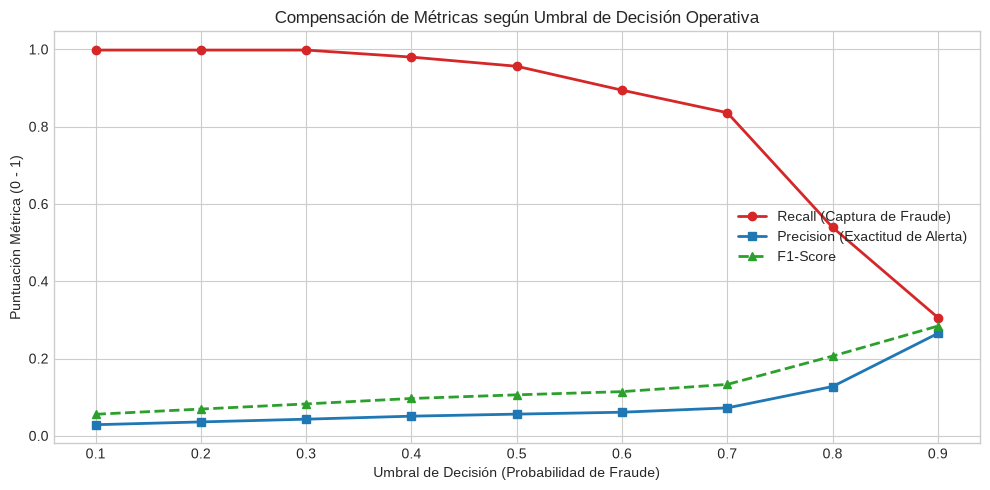

In [8]:
# Cargar el modelo final entrenado de la Unidad 2
model_u2 = load_artifact(MODEL_U2_ARTIFACT)
prep_u2 = load_artifact(PREPROCESSOR_U2_ARTIFACT)

# Tomamos una muestra de validación del conjunto de desarrollo
val_sample = train_df.sample(n=50000, seed=RANDOM_STATE + 99)
X_val_df = val_sample.select(SELECTED_FEATURES_U2).to_pandas()
y_val = val_sample["is_fraud"].to_numpy()

X_val_trans = prep_u2.transform(X_val_df)
y_val_probs = model_u2.predict_proba(X_val_trans)[:, 1]

thresholds = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]
thresh_records = []

total_val_cases = len(y_val)
total_val_frauds = int(np.sum(y_val))

for th in thresholds:
    y_pred_th = (y_val_probs >= th).astype(int)
    n_alerts = int(np.sum(y_pred_th))
    rec = recall_score(y_val, y_pred_th, zero_division=0)
    prec = precision_score(y_val, y_pred_th, zero_division=0)
    f1 = f1_score(y_val, y_pred_th, zero_division=0)
    tp = int(np.sum((y_pred_th == 1) & (y_val == 1)))
    fp = int(np.sum((y_pred_th == 1) & (y_val == 0)))
    
    thresh_records.append({
        "umbral_corte": th,
        "alertas_generadas": n_alerts,
        "pct_carga_revision_%": round(n_alerts / total_val_cases * 100, 2),
        "recall_fraude": round(rec, 4),
        "precision_fraude": round(prec, 4),
        "f1_score": round(f1, 4),
        "verdaderos_positivos_tp": tp,
        "falsos_positivos_fp": fp,
    })

df_thresholds = pd.DataFrame(thresh_records)
df_thresholds.to_csv(THRESHOLD_OPT_FILE, index=False)
print(f"Optimización de umbrales guardada en: {THRESHOLD_OPT_FILE}")
print("\n=== TABLA DE OPTIMIZACIÓN DE UMBRALES DE CORTE ===")
print(df_thresholds)

# Gráfico de curvas de compensación (Trade-off)
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(df_thresholds["umbral_corte"], df_thresholds["recall_fraude"], marker="o", color="#d62728", lw=2, label="Recall (Captura de Fraude)")
ax1.plot(df_thresholds["umbral_corte"], df_thresholds["precision_fraude"], marker="s", color="#1f77b4", lw=2, label="Precision (Exactitud de Alerta)")
ax1.plot(df_thresholds["umbral_corte"], df_thresholds["f1_score"], marker="^", color="#2ca02c", lw=2, linestyle="--", label="F1-Score")
ax1.set_xlabel("Umbral de Decisión (Probabilidad de Fraude)")
ax1.set_ylabel("Puntuación Métrica (0 - 1)")
ax1.set_title("Compensación de Métricas según Umbral de Decisión Operativa")
ax1.legend(loc="center right")
plt.tight_layout()
plt.show()


## 7. Análisis de Sensibilidad de Impacto Económico Hipotético

### Supuestos Académicos y Financieros:
1. **Costo de Revisión Manual por Alerta:** Estimado en **$5.00 USD** por alerta generada (tiempo del analista humano, validación telefónica y herramientas de verificación).
2. **Tasa de Recuperación / Prevención de Fraude:** Se asume que una intervención preventiva oportuna recupera el **85%** del importe fraudulento intentado.
3. **Costo de Falso Negativo (Fraude no detectado):** El banco asume el **100%** de la pérdida del importe mediante contracargo (*chargeback loss*).


=== ANÁLISIS DE IMPACTO ECONÓMICO HIPOTÉTICO ===
   umbral  fraude_prevenido_$  costo_analistas_$  beneficio_neto_$  \
0     0.1            43777.02            95625.0         -51847.98   
1     0.2            43777.02            76390.0         -32612.98   
2     0.3            43777.02            63700.0         -19922.98   
3     0.4            43532.61            52970.0          -9437.39   
4     0.5            43034.11            46800.0          -3765.89   
5     0.6            41877.39            40230.0           1647.39   
6     0.7            40992.38            31770.0           9222.38   
7     0.8            32928.46            11605.0          21323.46   
8     0.9            27608.89             3170.0          24438.89   

   roi_operativo_%  
0           -54.22  
1           -42.69  
2           -31.28  
3           -17.82  
4            -8.05  
5             4.09  
6            29.03  
7           183.74  
8           770.94  


/tmp/ipykernel_289705/1546494995.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_economic, x="umbral", y="beneficio_neto_$", palette="crest")


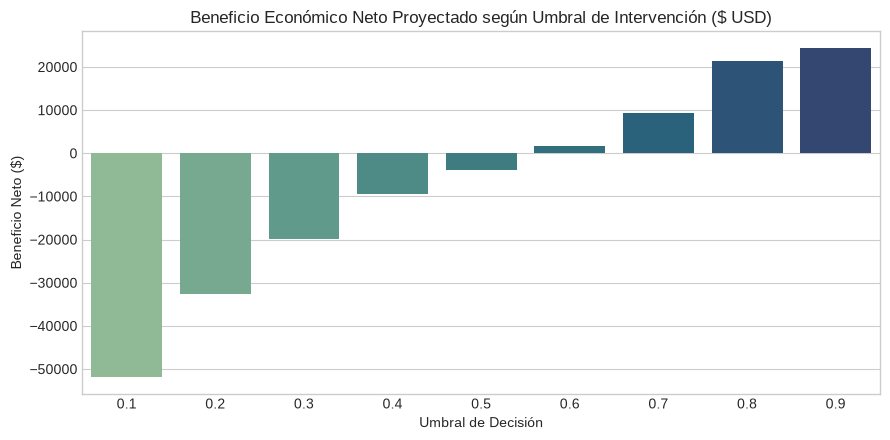

In [9]:
costo_alerta = 5.0
pct_recuperacion = 0.85
val_amounts = val_sample["Amount"].to_numpy()

economic_records = []
for th in thresholds:
    y_pred_th = (y_val_probs >= th).astype(int)
    
    # Fraudes detectados (TP) y fraude perdido (FN)
    tp_mask = (y_pred_th == 1) & (y_val == 1)
    fn_mask = (y_pred_th == 0) & (y_val == 1)
    fp_mask = (y_pred_th == 1) & (y_val == 0)
    
    monto_fraude_capturado = np.sum(val_amounts[tp_mask])
    monto_fraude_perdido = np.sum(val_amounts[fn_mask])
    
    ahorro_bruto = monto_fraude_capturado * pct_recuperacion
    costo_operativo = (np.sum(tp_mask) + np.sum(fp_mask)) * costo_alerta
    beneficio_neto = ahorro_bruto - costo_operativo
    
    economic_records.append({
        "umbral": th,
        "fraude_prevenido_$": round(ahorro_bruto, 2),
        "costo_analistas_$": round(costo_operativo, 2),
        "beneficio_neto_$": round(beneficio_neto, 2),
        "roi_operativo_%": round((beneficio_neto / costo_operativo * 100), 2) if costo_operativo > 0 else 0.0,
    })

df_economic = pd.DataFrame(economic_records)
print("=== ANÁLISIS DE IMPACTO ECONÓMICO HIPOTÉTICO ===")
print(df_economic)

# Gráfico del Beneficio Neto
plt.figure(figsize=(9, 4.5))
sns.barplot(data=df_economic, x="umbral", y="beneficio_neto_$", palette="crest")
plt.title("Beneficio Económico Neto Proyectado según Umbral de Intervención ($ USD)")
plt.xlabel("Umbral de Decisión")
plt.ylabel("Beneficio Neto ($)")
plt.tight_layout()
plt.show()


## 8. Generación de la Tabla Operativa Final (`transacciones_priorizadas.csv`)
Generamos la tabla de trabajo para los analistas humanos sobre el lote de inferencia:
- **Estrictamente sin la etiqueta de fraude `Is Fraud?`**.
- Incorpora `risk_score` (0 a 100), `cluster_id`, `nivel_prioridad` (`ALTA`, `MEDIA`, `BAJA`, `OUT_OF_COHORT_REVIEW`) y `accion_recomendada`.


In [10]:
# 1. Cargar lote de inferencia
df_infer = pl.read_csv(INFERENCE_SAMPLE_FILE)
print(f"Lote de inferencia cargado: {df_infer.shape[0]} registros")

# Añadir variables derivadas si no existen
if "amount_log" not in df_infer.columns:
    df_infer = add_u2_engineered_features(df_infer)

# 2. Separar cohorte positiva vs casos fuera de cohorte
mask_out = (df_infer["Amount"] <= 0).to_numpy()

n_records = len(df_infer)
risk_scores = np.zeros(n_records, dtype=float)
preds = np.zeros(n_records, dtype=int)
cluster_ids = np.zeros(n_records, dtype=int)
priorities = [""] * n_records
acciones = [""] * n_records

idx_pos = np.where(~mask_out)[0]
if len(idx_pos) > 0:
    df_pos = df_infer.filter(pl.col("Amount") > 0)
    X_pos_df = df_pos.select(SELECTED_FEATURES_U2).to_pandas()
    X_pos_trans = prep_u2.transform(X_pos_df)
    
    # Predicción y scoring con el modelo ganador U2
    probs_pos = model_u2.predict_proba(X_pos_trans)[:, 1]
    preds_pos = model_u2.predict(X_pos_trans)
    scores_pos = np.round(probs_pos * 100, 2)
    
    # Asignación de cluster conductual
    X_pos_cluster_scaled = cluster_preprocessor.transform(df_pos.select(all_cluster_features).to_pandas())
    clusters_pos = kmeans_final.predict(X_pos_cluster_scaled)
    
    for i, idx in enumerate(idx_pos):
        sc = scores_pos[i]
        risk_scores[idx] = sc
        preds[idx] = preds_pos[i]
        cluster_ids[idx] = clusters_pos[i]
        
        if sc >= 70.0:
            priorities[idx] = "ALTA"
            acciones[idx] = "Bloqueo preventivo de tarjeta y contacto urgente con el titular (Prioridad 1)"
        elif sc >= 40.0:
            priorities[idx] = "MEDIA"
            acciones[idx] = "Solicitud de verificación 2FA / Validación de biometría en app móvil"
        else:
            priorities[idx] = "BAJA"
            acciones[idx] = "Autorización automática sin fricción (Transacción legítima esperada)"

# Casos fuera de cohorte
idx_out_list = np.where(mask_out)[0]
for idx in idx_out_list:
    risk_scores[idx] = 0.0
    preds[idx] = -1
    cluster_ids[idx] = -1
    priorities[idx] = "OUT_OF_COHORT_REVIEW"
    acciones[idx] = "Auditoría manual de devolución / reembolso en módulo contable"

# 3. Construir tabla priorizada final
df_prioritized = df_infer.with_columns([
    pl.Series("risk_score", risk_scores),
    pl.Series("prediccion_modelo", preds),
    pl.Series("cluster_id", cluster_ids),
    pl.Series("nivel_prioridad", priorities),
    pl.Series("accion_recomendada", acciones),
])

cols_final = [
    "transaction_id",
    "Year",
    "Month",
    "Day",
    "Time",
    "Amount",
    "risk_score",
    "prediccion_modelo",
    "cluster_id",
    "nivel_prioridad",
    "accion_recomendada",
]

df_prioritized_final = df_prioritized.select(cols_final).sort("risk_score", descending=True)
df_prioritized_final.write_csv(PRIORITIZED_TXNS_FILE)

print(f"Tabla final de transacciones priorizadas exportada a: {PRIORITIZED_TXNS_FILE}")
print(f"Dimensiones finales: {df_prioritized_final.shape[0]} filas x {df_prioritized_final.shape[1]} columnas")
print("\nDistribución por nivel de prioridad:")
print(df_prioritized_final.group_by("nivel_prioridad").len().sort("len", descending=True))

print("\nPrimeras 5 transacciones de mayor riesgo:")
print(df_prioritized_final.head(5))


Lote de inferencia cargado: 1000 registros


Tabla final de transacciones priorizadas exportada a: /home/glender/ProyectosUNi/iaupeu/data/predictions/transacciones_priorizadas.csv
Dimensiones finales: 1000 filas x 11 columnas

Distribución por nivel de prioridad:
shape: (4, 2)
┌──────────────────────┬─────┐
│ nivel_prioridad      ┆ len │
│ ---                  ┆ --- │
│ str                  ┆ u32 │
╞══════════════════════╪═════╡
│ BAJA                 ┆ 799 │
│ ALTA                 ┆ 126 │
│ MEDIA                ┆ 70  │
│ OUT_OF_COHORT_REVIEW ┆ 5   │
└──────────────────────┴─────┘

Primeras 5 transacciones de mayor riesgo:
shape: (5, 11)
┌───────────────┬──────┬───────┬─────┬───┬──────────────┬────────────┬──────────────┬──────────────┐
│ transaction_i ┆ Year ┆ Month ┆ Day ┆ … ┆ prediccion_m ┆ cluster_id ┆ nivel_priori ┆ accion_recom │
│ d             ┆ ---  ┆ ---   ┆ --- ┆   ┆ odelo        ┆ ---        ┆ dad          ┆ endada       │
│ ---           ┆ i64  ┆ i64   ┆ i64 ┆   ┆ ---          ┆ i64        ┆ ---          ┆ ---       